## Week 4 Category-Share 
**My responsibility:** show the contributions of the different renewable energy sources solar and wind (total wind = onshore + offshore) to the total renewable energy generation in Great Britain.
**Expected Output:** one category-share chart exported to `visuals/`, a code, and a short interpretation of the findings.



## 1. Loading the cleaned dataset

In [1]:
#Loading the data
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

FILE_NAME = "cleaned_data.csv"

candidates = [
    Path("..") / "data" / "processed" / FILE_NAME,   # notebook inside notebooks/
    Path("data") / "processed" / FILE_NAME,          # notebook in the top folder
]
DATA_PATH = next((p for p in candidates if p.exists()), None)
assert DATA_PATH is not None, "cleaned_data.csv not found. Check that it is in data/processed/."

df = pd.read_csv(DATA_PATH, parse_dates=["utc_timestamp"])
print("Using:", DATA_PATH)
print("Shape:", df.shape)



Using: ..\data\processed\cleaned_data.csv
Shape: (50401, 22)


## 2. Select the study period (complete calendar years 2015 to 2019).

In [2]:
SOLAR = "GB_GBN_solar_generation_actual"
WIND = "GB_GBN_wind_generation_actual"       

year = df["utc_timestamp"].dt.year
period = df[(year >= 2015) & (year <= 2019)]

print("Period:", period["utc_timestamp"].min(), "to", period["utc_timestamp"].max())
print("Rows in period:", len(period), "| hours expected (5 years):", 5 * 365 * 24 + 24)   # 2016 was a leap year
print("Rows excluded (2014 and 2020):", len(df) - len(period))
print()
print("Missing hours inside the period - solar:", period[SOLAR].isna().sum(), "| wind:", period[WIND].isna().sum())

Period: 2015-01-01 00:00:00+00:00 to 2019-12-31 23:00:00+00:00
Rows in period: 43824 | hours expected (5 years): 43824
Rows excluded (2014 and 2020): 6577

Missing hours inside the period - solar: 48 | wind: 40


In [3]:
#Calculated the contributions for the sources
totals_mwh = pd.Series({"Solar": period[SOLAR].sum(), "Wind": period[WIND].sum()})   # NaN values are skipped
totals_twh = totals_mwh / 1_000_000
shares = totals_mwh / totals_mwh.sum() * 100

share_table = pd.DataFrame({
    "Total generation (TWh)": totals_twh,
    "Share of solar + wind (%)": shares,
}).sort_values("Share of solar + wind (%)", ascending=False)
#Table
share_table.round({"Total generation (TWh)": 2, "Share of solar + wind (%)": 1})

,Total generation (TWh),Share of solar + wind (%)
Wind,188.51,79.2
Solar,49.46,20.8


In [4]:
# Supporting table: Yearly contribution of each source
by_year = period.groupby(period["utc_timestamp"].dt.year)[[SOLAR, WIND]].sum() / 1_000_000
by_year["Solar share (%)"] = by_year[SOLAR] / (by_year[SOLAR] + by_year[WIND]) * 100
by_year.columns = ["Solar (TWh)", "Wind (TWh)", "Solar share (%)"]
by_year.index.name = "Year"
by_year.round(1)

,Solar (TWh),Wind (TWh),Solar share (%)
Year,,,
2015,7.6,31.6,19.4
2016,9.5,30.9,23.5
2017,10.1,39.3,20.5
2018,11.2,41.8,21.1
2019,11.0,44.9,19.7


**Result:** wind supplied about 79.2% and solar about 20.8% of the combined solar and wind generation. The yearly table shows the split is fairly stable, with solar's share between about 19% and 24% in each year.

## 3. Chart
A horizontal bar chart is used because it makes the difference between the two shares easy to compare. Each bar is labelled with its percentage and generation in TWh.

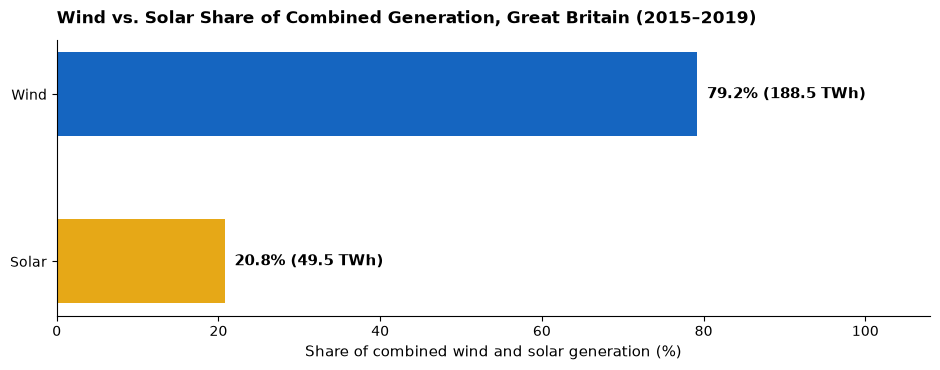

Saved to: ..\visuals\category_share_wind_solar.png


In [5]:
COLORS = {"Solar": "#E6A817", "Wind": "#1565C0"}
DPI = 300

title = "Wind vs. Solar Share of Combined Generation, Great Britain (2015–2019)"

fig, ax = plt.subplots(figsize=(9.5, 3.8))
order = share_table.index.tolist()[::-1]  # Solar bottom, Wind top
vals = [share_table.loc[n, "Share of solar + wind (%)"] for n in order]
twh = [share_table.loc[n, "Total generation (TWh)"] for n in order]

bars = ax.barh(order, vals, color=[COLORS[n] for n in order], height=0.5)
for bar, v, t in zip(bars, vals, twh):
    ax.text(
    v + 1.2,
    bar.get_y() + bar.get_height() / 2,
    f"{v:.1f}% ({t:.1f} TWh)",
    va="center",
    fontsize=11,
    fontweight="bold",
)

ax.set_xlim(0, 108)
ax.set_xlabel("Share of combined wind and solar generation (%)", fontsize=11)
ax.set_title(title, fontsize=12.5, fontweight="bold", loc="left", pad=12)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
out_dir = (
    Path("..") / "visuals" if (Path("..") / "data").exists() else Path("visuals")
)
out_dir.mkdir(parents=True, exist_ok=True)
out_path = out_dir / "category_share_wind_solar.png"
fig.savefig(out_path, dpi=DPI, bbox_inches="tight")
plt.show()
print("Saved to:", out_path)



**Figure 1:** Share of combined wind and solar generation in Great Britain, complete years 2015 to 2019 (hourly data).

## 4 Supporting chart: annual generation
Wind and solar generation each year, in TWh, 2015 to 2019

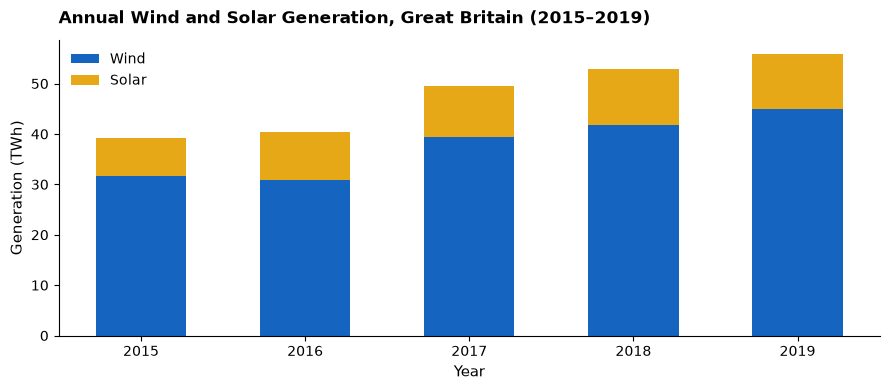

In [6]:
fig, ax = plt.subplots(figsize=(9, 4))

x = by_year.index.astype(str)
ax.bar(x, by_year["Wind (TWh)"], label="Wind", color="#1565C0", width=0.55)
ax.bar(
    x,
    by_year["Solar (TWh)"],
    bottom=by_year["Wind (TWh)"],
    label="Solar",
    color="#E6A817",
    width=0.55,
)

ax.set_ylabel("Generation (TWh)", fontsize=11)
ax.set_xlabel("Year", fontsize=11)
ax.set_title(
    "Annual Wind and Solar Generation, Great Britain (2015–2019)",
    fontsize=12.5,
    fontweight="bold",
    loc="left",
    pad=12,
)
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
fig.savefig(
    out_dir / "yearly_generation_wind_solar.png", dpi=300, bbox_inches="tight"
)
plt.show()

## 5. Interpretation
Over the complete years 2015 to 2019, wind supplied about 79.2% of the combined solar and wind generation (about 188.5 TWh) and solar about 20.8% (about 49.5 TWh). This indicates Great Britain's solar and wind electricity depends largely on wind, so total renewable output rises and falls with the weather, and solar adds a smaller, daylight-only contribution. The split was fairly stable, with solar's yearly share between about 19.4% and 23.5%. The chart has limits: it shows generation only and not demand, it only covers Great Britain, and because all available rows were used, about 48 missing solar hours and 40 missing wind hours were skipped, so the two sources are not summed over exactly the same hours.